In [3]:
import os
# 0: 모든 로그 출력, 1: INFO 로그 숨김, 2: WARNING 로그 추가 숨김, 3: ERROR 로그만 출력
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import numpy as np
print(np.__version__)

import torch; 
print('Torch:', torch.__version__); 
print('------CUDA:', torch.version.cuda); 
print('------GPU:', torch.cuda.is_available()); 
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE')

import tensorflow as tf
print('TensorFlow:', tf.__version__)
print('-----GPU:', tf.config.list_physical_devices('GPU'))


import ultralytics
print(ultralytics.__version__)

2.5.3
Torch: 2.14.0+cu132
------CUDA: 13.2
------GPU: True
Device: NVIDIA GeForce RTX 3070
TensorFlow: 2.21.0
-----GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
8.4.152


# **OpenCV test**

이미지 크기: (357, 559, 3)


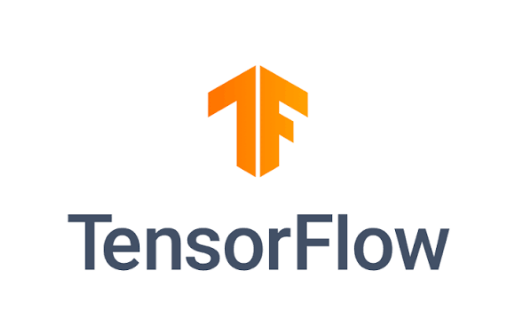

In [5]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("./imgs/sample.png")

print("이미지 크기:", img.shape)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# **YOLO test**


image 1/1 /workspace/lec_dl_docker/imgs/sample.png: 416x640 (no detections), 21.1ms
Speed: 5.6ms preprocess, 21.1ms inference, 2.3ms postprocess per image at shape (1, 3, 416, 640)


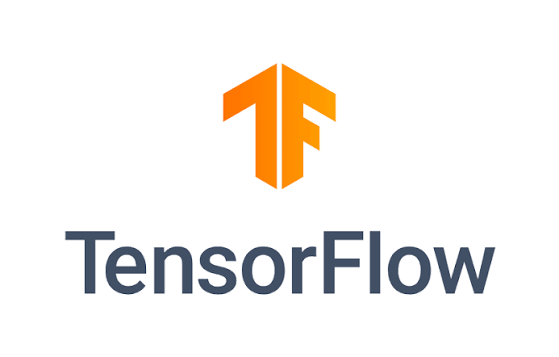

In [2]:
from ultralytics import YOLO
from IPython.display import display, Image

model = YOLO("yolo11n.pt")

results = model("./imgs/sample.png", device=0)
#results[0].show()

results[0].save(filename="./imgs/result.png")  #이미지저장
display(Image(filename="./imgs/result.png"))   #jupyte에서 보기


image 1/1 /workspace/lec_dl_docker/imgs/sample2.jpg: 544x640 1 person, 1 cat, 2 dogs, 3 cows, 25.0ms
Speed: 6.1ms preprocess, 25.0ms inference, 59.8ms postprocess per image at shape (1, 3, 544, 640)


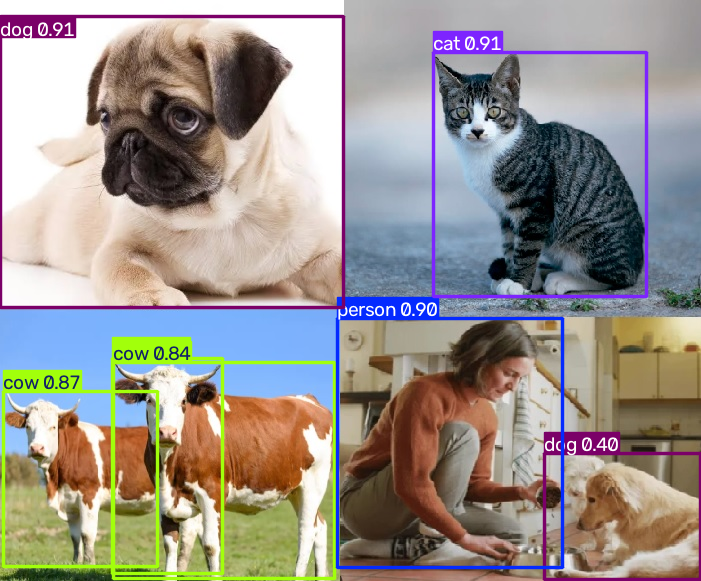

In [7]:
from ultralytics import YOLO
from IPython.display import Image, display

model = YOLO("yolo26n.pt")
results = model(
    "./imgs/sample2.jpg",
    device=0
)

#results[0].show()
results[0].save(filename="./imgs/result.png")  #이미지저장
display(Image(filename="./imgs/result.png"))   #jupyte에서 보기

# **HuggingFace**

In [8]:
#터미널에서 설치 : pip install -U ipywidgets jupyter

In [9]:
import transformers
import huggingface_hub
import datasets
import sentence_transformers
import accelerate

print("Transformers :", transformers.__version__)
print("HuggingFace Hub :", huggingface_hub.__version__)
print("Datasets :", datasets.__version__)
print("Sentence Transformers :", sentence_transformers.__version__)
print("Accelerate :", accelerate.__version__)

Transformers : 5.17.0
HuggingFace Hub : 1.31.0
Datasets : 5.0.1
Sentence Transformers : 6.0.1
Accelerate : 1.15.0


# **Agent 샘플**

In [10]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# -------------------------
# 1. Agent 상태
# -------------------------
class State(TypedDict):
    question: str
    answer: str

# -------------------------
# 2. Agent가 실행할 함수
# -------------------------
def agent(state: State):
    question = state["question"]
    if "파이썬" in question:
        answer = "파이썬에 대한 질문입니다."
    elif "딥러닝" in question:
        answer = "딥러닝에 대한 질문입니다."
    else:
        answer = "제가 처리할 수 있는 질문입니다."
    return {
        "answer": answer
    }

# -------------------------
# 3. Agent Graph 생성
# -------------------------
graph = StateGraph(State)
graph.add_node("agent", agent)
graph.add_edge(START, "agent")
graph.add_edge("agent", END)


# -------------------------
# 4. Agent 실행
# -------------------------
app = graph.compile()
result = app.invoke({
    "question": "파이썬이 무엇인가요?",
    "answer": ""
})

print(result)

{'question': '파이썬이 무엇인가요?', 'answer': '파이썬에 대한 질문입니다.'}


# **Vector DB — Chroma**

In [11]:
import chromadb
print("ChromaDB :", chromadb.__version__)

client = chromadb.PersistentClient(path="./chroma_db")
collection = client.get_or_create_collection(name="my_documents")

collection.add(
    ids=["1", "2", "3"],
    documents=[
        "파이썬은 프로그래밍 언어입니다.",
        "LangChain은 LLM 애플리케이션 개발 프레임워크입니다.",
        "Chroma는 벡터 데이터베이스입니다."
    ]
)
print("저장 완료")

result = collection.query(
    query_texts=["벡터 데이터베이스"],
    n_results=2
)
print(result["documents"])

ChromaDB : 1.5.9
저장 완료
[['파이썬은 프로그래밍 언어입니다.', 'LangChain은 LLM 애플리케이션 개발 프레임워크입니다.']]


# **Ollama + 경량 오픈소스 LLM**

In [12]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain_ollama import ChatOllama

# -----------------------------
# 1. Tool 만들기
# -----------------------------
@tool
def calculator(a: int, b: int) -> int:
    """두 숫자를 더합니다."""
    return a + b

# -----------------------------
# 2. Ollama LLM
# -----------------------------
llm = ChatOllama(
    model="qwen3:4b",
    base_url="http://host.docker.internal:11434"
)

# -----------------------------
# 3. Agent 생성
# -----------------------------
agent = create_agent(
    model=llm,
    tools=[calculator],
    system_prompt="당신은 친절한 AI Agent입니다."
)

# -----------------------------
# 4. 질문
# -----------------------------
result = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "1234와 5678을 더해줘"
        }
    ]
})

# -----------------------------
# 5. 결과 출력
# -----------------------------
print(result["messages"][-1].content)

1234와 5678를 더하면 6912입니다. 😊
